# 42. Placebo-event reference: do the decomposition and the ranking reversal arise from event placement alone?

I ask whether the decomposition (standard AUC = pre-onset + in progress) and the 24-hour ranking reversal reflect information about actual declines, or whether the label structure (window length, spacing, clustering) or the volatility regime alone produces them. To find out, I leave the scores unchanged, move only the event positions, compute the same statistics on these placebo events and compare them with the real values. The analysis is exploratory and uses Binance spot BTCUSDT one-minute data over the development period only (2023-01 to 2026-04); the preregistered plans (OSF TB245, BKJUQ) stay unchanged.

I draw from two placebo families, 1,000 draws each, separately for each definition:
- Family (a) is a circular shift: I roll the label codes on the ordered common minutes (notebook 33) by k ~ U[7 days, L − 7 days] (L = number of common minutes). The shift keeps event spacing, window structure and clustering and breaks only the alignment with the scores.
- Family (b) is a regime-matched relocation: I move each event's breach to another minute within ±30 days and at least 1 day away, where the first window minute (b − 240) has the same 24-hour RV decile as for the real event, the window lies inside the evaluation period with at least 190 (90%) common minutes, the placebo breach is more than one day from every real breach of both definitions, and the window does not overlap placebo windows already placed (placebo breaches more than 210 minutes apart). I place the events with the fewest admissible minutes first (ties at random). The search widens from the same decile within ±30 days to the same decile within ±60 days and then to deciles ±1 within ±60 days; I leave an event with no minute in any tier out of that draw and record the counts per tier. Each event keeps its onset-to-breach gap g, so π stays nearly the same. This family does not preserve the spacing between events (real breaches are at least 1,440 minutes apart under the refractory rule, placebo breaches only more than 210) and keeps clustering only roughly, within the ±30-day moves; family (a) is the reference that preserves them, so the two families match different things.
- In both families I exclude real positive minutes from the placebo negatives unless they become placebo positives; all other common minutes are negatives.

For the 4-hour and 24-hour definitions I compute the standard, pre-onset, in-progress and within-regime pre-onset AUC of M0 and GBM; π; M0's S_in and AUC_in − AUC_pre; and the GBM − M0 differences in the four AUCs.

I fix the readings before the results and record them in `42_SPEC.json`. R1 asks whether M0's AUC_in − AUC_pre (4-hour definition) lies above the 97.5th percentile of both families, R2 whether M0's within-regime pre-onset AUC (4-hour definition) lies above the 97.5th percentile of family (b), and R3 whether the 24-hour GBM − M0 standard and pre-onset AUC differences lie beyond the 97.5th and 2.5th percentiles of family (b). When placement quality falls short of fixed limits (`3_placement_check.csv`), I attach a placement caution to that definition's family (b) readings. The placebo distributions come from one series and are not independent samples, so I treat the percentiles as a reference range and the empirical p-values as descriptive. I call a value inside the range "not distinguishable from the placebo reference", never "reproduced by placebo events", and a value beyond it does not establish predictive skill.

The inputs are the spot cache, the notebook 02 event catalog and the notebook 16 frozen models. I write results only to `placebo_reference_v1`; outputs and figures contain no prices.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib

OUT = SPOT_BASE / 'placebo_reference_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M22 = SPOT_BASE / 'peak_window_v1'
M33 = SPOT_BASE / 'shapley_decomposition_v1'
DNAME, DCL = '4pct', 0.04
H_REF, H_24 = 240, 1440; H_LIST = [H_REF, H_24]
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']        # common-minute set of notebooks 29, 32, 33 (Table 6)
A_NAME, B_NAME = 'M3_GBM_rich', 'M0_VF_logit'
SEED = 20261142
N_PLACEBO = 1000                      # per family and definition
SHIFT_MIN_D = 7                       # family (a): k ~ U[7 days, L - 7 days] common minutes
MOVE_MAX_D = 30; MOVE_MIN_D = 1       # family (b): new breach within +-30 days, at least 1 day away
MIN_COVER = 190                       # family (b): common minutes in the placebo window (of 211)
WINDOW_MIN = LEAD_MAX - LEAD_MIN + 1  # 211
SEP = WINDOW_MIN - 1                  # two windows [b-240, b-30] overlap iff their breaches are at most 210 minutes apart
SEP_REAL = 1440                       # family (b): a placebo breach at least one day from every catalog breach (both definitions)
MOVE_FALLBACK_D = 60                  # family (b): search range for an event with no admissible minute within +-30 days
MIN_FINITE = 0.95                     # a reading needs a finite real value and at least this share of finite placebo draws
BLOCK_DAYS = 7
MOCK_BYPASS = ()                      # empty on Colab; only the synthetic test run lists guard names here, and every bypass is printed and recorded
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
GUARDS = []


def guard(name, ok, msg):
    ok = bool(ok); byp = (not ok) and (name in MOCK_BYPASS)
    GUARDS.append(dict(guard=name, passed=ok, bypassed_in_mock=byp, detail=str(msg)))
    if ok:
        return True
    if byp:
        print(f'Guard "{name}" bypassed: {msg} (synthetic test run only)', flush=True)
        return False
    raise RuntimeError(f'GUARD FAIL: {msg}')


for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M22 / '2_per_minute_by_window.csv', M33 / '1_decomposition_point.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16, 22 and 33 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Placebo-event reference for the decomposition and the 24-hour ranking reversal (exploratory; development sample)',
        'inputs': 'spot cache, notebook-2 catalog, notebook-16 frozen models; stored results of notebooks 22 and 33 for guards; holdouts and the prospective folder not read',
        'minutes': 'notebook-33 common minutes; scores unchanged; only event positions move',
        'family_a': f'label codes on the ordered common minutes rolled by k ~ U[{SHIFT_MIN_D} days, L - {SHIFT_MIN_D} days] minutes (L = number of common minutes); spacing, windows and clustering kept',
        'family_b': f'each event with positives on the common minutes gets a new breach minute within +-{MOVE_MAX_D} days and at least {MOVE_MIN_D} day away, with the same 24-hour RV decile at the first window minute '
                    f'(first window minute with a decile if that one has none; no decile condition if none has), window inside the evaluation period, at least {MIN_COVER} of {WINDOW_MIN} window minutes common, '
                    f'placebo breach more than {SEP_REAL} minutes from every catalog breach of either definition, placebo windows not overlapping each other (breaches more than {SEP} minutes apart; '
                    f'catalog breaches are at least 1,440 minutes apart, so placebo spacing is looser than real spacing); events placed in order of their number of admissible minutes (fewest first, ties random); '
                    f'admissible minutes in three tiers: same decile within +-{MOVE_MAX_D} days, else same decile within +-{MOVE_FALLBACK_D} days, else decile within +-1 within +-{MOVE_FALLBACK_D} days; '
                    'an event with no free minute in any tier is left out of that draw; tier use and omissions counted; '
                    'onset-to-breach gap of each event kept; spacing and clustering between events are not preserved (family a preserves them)',
        'labels': 'placebo window minutes before the moved onset are pre-onset positives, the rest in-progress positives; real positive minutes that are not placebo positives are excluded; all other common minutes negative',
        'draws': {'per_family_and_definition': N_PLACEBO}, 'definitions': H_LIST,
        'readings': {'language': 'within the placebo range means not distinguishable from the placebo reference, never reproduced by it; beyond the range does not establish predictive skill',
                     'R1': 'H=240: real M0 AUC_in - AUC_pre above the 97.5th placebo percentile in both families -> beyond both placebo references; otherwise not distinguishable from the placebo reference',
                     'R2': 'H=240: real M0 within-regime pre-onset AUC above the 97.5th percentile of family b -> beyond the regime-matched placebo reference; otherwise not distinguishable from it (family a reported); '
                           'descriptive ratio (median_b M0 pre-onset AUC - 0.5) / (real - 0.5) of excess AUCs, not a decomposition of explanation',
                     'R3': 'H=1440: real GBM - M0 standard-AUC difference above the 97.5th percentile of family b AND real pre-onset difference below its 2.5th percentile -> both legs beyond the regime-matched placebo reference; '
                           'one of the two -> that leg beyond the reference, the other not distinguishable from it; neither -> neither leg distinguishable from the reference; '
                           'not applicable if the real point estimates are not (+, -) (family a reported); descriptive: share of draws with standard difference > 0 and pre-onset difference < 0, '
                           'and share with both differences at least as extreme as the real ones',
                     'undetermined': f'a reading is undetermined if the real value is not finite or fewer than {MIN_FINITE:.0%} of placebo draws are finite',
                     'placement_quality_b': 'caution for a definition if the mean placed share is below 95%, or the mean share placed at tier 3 exceeds 10%, '
                                            'or the median relative difference of placebo positives from the real count exceeds 5%, or the median absolute difference of pi from the real pi exceeds 0.02',
                     'p_values': 'empirical (1 + #(placebo >= real)) / (N + 1) and the lower-tail analogue, descriptive (draws from one series are not independent)'},
        'guards': 'notebook-22 per-minute AUCs; notebook-33 GBM - M0 points; the rank engine equals make_parts/stats_from on the real labels',
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'holdouts': 'not used', 'prospective_folder': 'not read',
        'status': 'exploratory; development sample only; no confirmatory plan changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '42_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'42_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16], '| skipped checks:', MOCK_BYPASS if MOCK_BYPASS else 'none')

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/placebo_reference_v1 | spec sha256 7a8552f5ba6895d9 | skipped checks: none


## 0. Reproduce scores, labels and deciles

I use the same code as section 0 of notebooks 32, 33 and 36.

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in TCOLS:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


def in_decline_mask(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


def event_of_minute(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left')
    out = np.full(len(T), -1, np.int64); ok = (y_ == 1) & (pos < len(br)); out[ok] = pos[ok]
    return out


E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CAT = {H: catalog_H(H) for H in H_LIST}
guard('catalog_nb2', len(CAT[H_REF]) == len(E_ref) and all(np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS),
      'H=240 catalog differs from the notebook-2 catalog')
EV = {H: events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True) for H in H_LIST}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
guard('m0_refit_nb16', np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9),
      'M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
guard('gbm_sha_nb16', sha256_file(mp) == cfg3['model_sha256'], 'notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
del Xl, F, sg, g3

PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}; EVOF = {}
for H in H_LIST:
    yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
    LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64); EVOF[H] = event_of_minute(CAT[H], yH)
MC = EVM & (DEC >= 0)
for sname in PSCORES:
    MC &= np.isfinite(S[sname])
print(f'section 0 scores ready ({time.time() - t_:.0f}s); development events:', {H: len(EV[H]) for H in H_LIST}, '| common valid minutes:', int(MC.sum()))

section 0 scores ready (71s); development events: {240: 83, 1440: 218} | common valid minutes: 1750612


### 0b. Rank calculator

I sort the scores once, so each label set gives an exact AUC from one pass of cumulative negative counts.

In [3]:
from sklearn.metrics import roc_auc_score


class RankEngine:
    """Exact AUCs for many label sets on one fixed minute set (ties count one half)."""

    def __init__(self, s, dec):
        n = len(s); self.n = n; self.dec = np.asarray(dec, np.int64)
        o = np.argsort(s, kind='stable'); sv = s[o]
        new = np.r_[True, sv[1:] != sv[:-1]]; st = np.flatnonzero(new); en = np.r_[st[1:], n]; gid = np.cumsum(new) - 1
        self.o = o; self.pos = np.empty(n, np.int64); self.pos[o] = np.arange(n); self.gs = st[gid]; self.ge = en[gid]
        od = np.lexsort((s, self.dec)); dv = self.dec[od]; sd = s[od]
        newd = np.r_[True, (sd[1:] != sd[:-1]) | (dv[1:] != dv[:-1])]; std_ = np.flatnonzero(newd); end_ = np.r_[std_[1:], n]; gidd = np.cumsum(newd) - 1
        segnew = np.r_[True, dv[1:] != dv[:-1]]; segst = np.flatnonzero(segnew); segid = np.cumsum(segnew) - 1
        self.od = od; self.posd = np.empty(n, np.int64); self.posd[od] = np.arange(n); self.gsd = std_[gidd]; self.ged = end_[gidd]; self.seg0 = segst[segid]

    def stats(self, code):
        neg = code == 0; pre = np.flatnonzero(code == 1); inn = np.flatnonzero(code == 2)
        cum = np.zeros(self.n + 1, np.int64); np.cumsum(neg[self.o], out=cum[1:])
        def v(idx):
            p = self.pos[idx]; a = cum[self.gs[p]]; b = cum[self.ge[p]]
            return (a + 0.5 * (b - a)).sum()
        nN = float(cum[-1]); npre, nin = len(pre), len(inn); sp = v(pre); si = v(inn)
        cumd = np.zeros(self.n + 1, np.int64); np.cumsum(neg[self.od], out=cumd[1:])
        p = self.posd[pre]; base = cumd[self.seg0[p]]; a = cumd[self.gsd[p]] - base; tie = cumd[self.ged[p]] - cumd[self.gsd[p]]
        swr = (a + 0.5 * tie).sum(); dwr = float((np.bincount(self.dec[neg], minlength=10) * np.bincount(self.dec[pre], minlength=10)).sum())
        r = lambda x, y: x / y if y > 0 else np.nan
        std = r(sp + si, (npre + nin) * nN); aprei = r(sp, npre * nN); ain = r(si, nin * nN); pi = r(nin, npre + nin)
        return dict(auc_standard=std, auc_pre=aprei, auc_in=ain, share_in=pi, auc_pre_within_regime=r(swr, dwr),
                    in_minus_pre=ain - aprei, S_in=r(pi * (ain - 0.5), std - 0.5) if np.isfinite(ain) else np.nan,
                    n_pre=npre, n_in=nin, n_neg=nN)


# ---- guard (iv): small random cases against sklearn (ties included)
_u = np.random.default_rng(SEED + 99); _e = []
for trial in range(40):
    n = int(_u.integers(200, 700)); s_ = np.round(_u.normal(size=n), 1); c_ = _u.choice([0, 0, 0, 0, 1, 2, -1], n); d_ = _u.integers(0, 10, n)
    rr = RankEngine(s_, d_).stats(c_); k = c_ >= 0; y = c_[k] > 0; kp = c_ != 2
    if 0 < y.sum() < len(y):
        _e.append(abs(rr['auc_standard'] - roc_auc_score(y, s_[k])))
    yp = c_[kp & k] > 0
    if 0 < yp.sum() < len(yp):
        _e.append(abs(rr['auc_pre'] - roc_auc_score(yp, s_[kp & k])))
    num = den = 0.0
    for q in range(10):
        kq = (d_ == q) & (c_ >= 0) & (c_ != 2); a_, b_ = int((c_[kq] == 1).sum()), int((c_[kq] == 0).sum())
        if a_ and b_:
            num += roc_auc_score(c_[kq] == 1, s_[kq]) * a_ * b_; den += a_ * b_
    if den:
        _e.append(abs(rr['auc_pre_within_regime'] - num / den))
guard('engine_vs_sklearn', max(_e) <= 1e-12, f'rank engine differs from sklearn by {max(_e):.2e}')

# ---- guards (i)-(iii)
for H in H_LIST:
    for sname in (B_NAME, A_NAME):
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
        rr = RankEngine(S[sname][m], DEC[m]).stats(LAB[H][m]); ref = PM22[(PM22.H == H) & (PM22.score == sname)]
        dmax = max(abs(rr[k] - float(ref.iloc[0][k])) for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']) if len(ref) == 1 else np.inf
        guard('per_minute_nb22', dmax <= 1e-9, f'rank engine differs from notebook 22 (H={H}, {sname}) by {dmax:.2e}')
ENG = {sn: RankEngine(S[sn][MC], DEC[MC]) for sn in (B_NAME, A_NAME)}
CODE = {H: LAB[H][MC].copy() for H in H_LIST}
REAL = {}
PT33 = pd.read_csv(M33 / '1_decomposition_point.csv'); PT33 = PT33[(PT33.h1 == H_REF) & (PT33.h2 == H_24)].iloc[0]
for H, tag in ((H_REF, 'h1'), (H_24, 'h2')):
    ra = ENG[A_NAME].stats(CODE[H]); rb = ENG[B_NAME].stats(CODE[H]); REAL[H] = (rb, ra)
    q = dict(pi=ra['share_in'], D=ra['auc_standard'] - rb['auc_standard'], dpre=ra['auc_pre'] - rb['auc_pre'], din=ra['auc_in'] - rb['auc_in'])
    dmax = max(abs(q[k] - float(PT33[f'{k}_{tag}'])) for k in q)
    guard('nb33_point', dmax <= 1e-9, f'GBM - M0 point differences at H={H} differ from notebook 33 by {dmax:.2e}')
    for sn, rr in ((B_NAME, rb), (A_NAME, ra)):
        ref = stats_from(make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]), ONES)
        dmax = max(abs(rr[k] - ref[k]) for k in ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'auc_pre_within_regime'])
        guard('engine_vs_make_parts', dmax <= 1e-9, f'rank engine differs from make_parts at H={H} ({sn}) by {dmax:.2e}')
print(f'PASS: rank engine equals sklearn, notebook 22, notebook 33 and make_parts ({time.time() - t_:.0f}s)')
for H in H_LIST:
    rb, ra = REAL[H]
    print(f'real H={H}: M0 standard {rb["auc_standard"]:.4f} pre {rb["auc_pre"]:.4f} in {rb["auc_in"]:.4f} within-regime pre {rb["auc_pre_within_regime"]:.4f} S_in {rb["S_in"]:.3f} pi {rb["share_in"]:.3f} | '
          f'GBM - M0 standard {ra["auc_standard"] - rb["auc_standard"]:+.4f} pre {ra["auc_pre"] - rb["auc_pre"]:+.4f}')

PASS: rank engine equals sklearn, notebook 22, notebook 33 and make_parts (97s)
real H=240: M0 standard 0.7633 pre 0.6728 in 0.8914 within-regime pre 0.5924 S_in 0.615 pi 0.414 | GBM - M0 standard -0.0081 pre -0.0189
real H=1440: M0 standard 0.6958 pre 0.7068 in 0.6948 within-regime pre 0.6473 S_in 0.909 pi 0.914 | GBM - M0 standard +0.0568 pre -0.0903


## 1. Placebo events and statistics (two families × two definitions × 1,000 draws)

In [4]:
t_ = time.time()
MC_IDX = np.flatnonzero(MC); N_MC = len(MC_IDX)
MCMAP = np.full(len(T), -1, np.int64); MCMAP[MC_IDX] = np.arange(N_MC)
MC_CUM = np.r_[0, np.cumsum(MC)]
I_FIRST = int(np.searchsorted(T, ts(EVAL_START).value, 'left')); I_LAST = int(np.searchsorted(T, EVAL_LAST, 'left')) - 1     # minutes of the evaluation period


def events_on_common(H):
    """Catalog rows of events with positives on the common minutes, their breach index on the minute grid, gap and window decile."""
    rows = np.unique(EVOF[H][MC & (LAB[H] > 0)])
    br = ((CAT[H].breach_utc.astype('int64').to_numpy()[rows] - T[0]) // NS).astype(np.int64)
    g = CAT[H].onset_to_breach_minutes.to_numpy()[rows].astype(np.int64)
    q = np.full(len(rows), -1, np.int64)
    for i, b in enumerate(br):
        d = DEC[b - LEAD_MAX:b - LEAD_MIN + 1]; ok = np.flatnonzero(d >= 0)
        if len(ok):
            q[i] = d[ok[0]]
    return rows, br, g, q


def static_candidates(H, br, q):
    """Admissible new breach indices per event in three tiers, before the placebo-placebo overlap check:
    tier 1 = same decile within +-MOVE_MAX_D days; tier 2 = same decile within +-MOVE_FALLBACK_D days; tier 3 = decile within +-1 within +-MOVE_FALLBACK_D days."""
    all_br = np.unique(np.concatenate([((CAT[h].breach_utc.astype('int64').to_numpy() - T[0]) // NS).astype(np.int64) for h in H_LIST]))
    near_real = np.zeros(len(T) + 1, np.int64)                     # difference array: minutes within SEP_REAL of a catalog breach of either definition
    np.add.at(near_real, np.clip(all_br - SEP_REAL, 0, len(T)), 1); np.add.at(near_real, np.clip(all_br + SEP_REAL + 1, 0, len(T)), -1)
    near_real = np.cumsum(near_real[:-1]) > 0
    def admissible(b, qe, D, tol):
        j = np.r_[np.arange(b - D * 1440, b - MOVE_MIN_D * 1440 + 1), np.arange(b + MOVE_MIN_D * 1440, b + D * 1440 + 1)]
        j = j[(j - LEAD_MAX >= I_FIRST) & (j - LEAD_MIN <= I_LAST)]
        cover = MC_CUM[j - LEAD_MIN + 1] - MC_CUM[j - LEAD_MAX]
        ok = (cover >= MIN_COVER) & ~near_real[j]
        if qe >= 0:
            ok &= np.abs(DEC[j - LEAD_MAX] - qe) <= tol
        return j[ok].astype(np.int64)
    tiers = [[admissible(b, qe, MOVE_MAX_D, 0), admissible(b, qe, MOVE_FALLBACK_D, 0), admissible(b, qe, MOVE_FALLBACK_D, 1)] for b, qe in zip(br, q)]
    return tiers


OFFS = np.arange(-LEAD_MAX, -LEAD_MIN + 1)


def placebo_code_b(H, rng, info):
    rows, br, g, q, tiers = info
    taken = np.zeros(len(T), bool); placed_j = []; placed_e = []; tier_used = np.zeros(4, np.int64)      # counts of tier 1, 2, 3 and not placed
    ncand = np.array([len(tt[0]) for tt in tiers])
    for e in np.lexsort((rng.random(len(rows)), ncand)):          # events with the fewest tier-1 minutes first (ties in random order): fewer collisions
        for k_, c in enumerate(tiers[e]):
            c = c[~taken[c]] if len(c) else c
            if len(c):
                j = int(c[rng.integers(len(c))]); taken[max(0, j - SEP):j + SEP + 1] = True; placed_j.append(j); placed_e.append(e); tier_used[k_] += 1
                break
        else:
            tier_used[3] += 1
    code = np.where(CODE[H] > 0, -1, CODE[H])
    if placed_j:
        J = np.array(placed_j); Gp = g[np.array(placed_e)]
        I = J[:, None] + OFFS[None, :]; lab = np.where(I < (J - Gp)[:, None], 1, 2); M = MCMAP[I]; sel = M >= 0
        code[M[sel]] = lab[sel]
    return code, len(placed_j), tier_used


def placebo_code_a(H, rng):
    k = int(rng.integers(SHIFT_MIN_D * 1440, N_MC - SHIFT_MIN_D * 1440 + 1))
    code = np.roll(CODE[H], k); code[(CODE[H] > 0) & (code == 0)] = -1
    return code, k


INFO = {}; WIDENED = {}; NONE = {}
for H in H_LIST:
    rows, br, g, q = events_on_common(H); tiers = static_candidates(H, br, q); INFO[H] = (rows, br, g, q, tiers)
    nc = np.array([[len(c) for c in tt] for tt in tiers]); WIDENED[H] = int((nc[:, 0] == 0).sum()); NONE[H] = int((nc.max(axis=1) == 0).sum())
    print(f'H={H}: {len(rows)} events on the common minutes; tier-1 admissible minutes per event: median {np.median(nc[:, 0]):.0f}, min {nc[:, 0].min()}; '
          f'no tier-1 minute: {WIDENED[H]}; no minute in any tier: {NONE[H]}; events without a decile {int((q < 0).sum())}', flush=True)

KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime', 'share_in', 'S_in', 'in_minus_pre']
DRAWS = []
for fam in ('a', 'b'):
    for H in H_LIST:
        rng = np.random.default_rng(SEED + (1 if fam == 'a' else 2) * 10000 + H)
        for i in range(N_PLACEBO):
            if fam == 'a':
                code, k = placebo_code_a(H, rng); extra = dict(shift_minutes=k, placed=np.nan, not_placed=np.nan)
            else:
                code, npl, tu = placebo_code_b(H, rng, INFO[H]); extra = dict(shift_minutes=np.nan, placed=npl, tier1=tu[0], tier2=tu[1], tier3=tu[2], not_placed=tu[3])
            rb = ENG[B_NAME].stats(code); ra = ENG[A_NAME].stats(code)
            row = dict(family=fam, H=H, draw=i, **extra, n_pre=rb['n_pre'], n_in=rb['n_in'])
            row.update({f'm0_{k}': rb[k] for k in KEYS}); row.update({f'gbm_{k}': ra[k] for k in KEYS})
            row.update({f'd_{k}': ra[k] - rb[k] for k in ('auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime')})
            DRAWS.append(row)
        print(f'family {fam}, H={H}: {N_PLACEBO} draws ({time.time() - t_:.0f}s)', flush=True)
PD_ = pd.DataFrame(DRAWS); PD_.to_csv(OUT / '1_placebo_draws.csv', index=False)

H=240: 83 events on the common minutes; tier-1 admissible minutes per event: median 3749, min 191; no tier-1 minute: 0; no minute in any tier: 0; events without a decile 0
H=1440: 218 events on the common minutes; tier-1 admissible minutes per event: median 5095, min 360; no tier-1 minute: 0; no minute in any tier: 0; events without a decile 0
family a, H=240: 1000 draws (92s)
family a, H=1440: 1000 draws (185s)
family b, H=240: 1000 draws (278s)
family b, H=1440: 1000 draws (373s)


## 2. Real values against the placebo distributions, with the pre-specified readings

In [5]:
STATS = [(H_REF, 'm0_in_minus_pre'), (H_REF, 'm0_S_in'), (H_REF, 'm0_auc_standard'), (H_REF, 'm0_auc_pre'), (H_REF, 'm0_auc_in'), (H_REF, 'm0_auc_pre_within_regime'), (H_REF, 'm0_share_in'),
         (H_REF, 'd_auc_standard'), (H_REF, 'd_auc_pre'), (H_REF, 'd_auc_in'), (H_REF, 'd_auc_pre_within_regime'),
         (H_24, 'm0_in_minus_pre'), (H_24, 'm0_auc_pre'), (H_24, 'm0_auc_pre_within_regime'), (H_24, 'm0_share_in'), (H_24, 'gbm_auc_standard'), (H_24, 'm0_auc_standard'),
         (H_24, 'd_auc_standard'), (H_24, 'd_auc_pre'), (H_24, 'd_auc_in'), (H_24, 'd_auc_pre_within_regime')]


def real_value(H, col):
    rb, ra = REAL[H]
    if col.startswith('m0_'):
        return rb[col[3:]]
    if col.startswith('gbm_'):
        return ra[col[4:]]
    return ra[col[2:]] - rb[col[2:]]


REF_ROWS = []
for H, col in STATS:
    x = real_value(H, col)
    for fam in ('a', 'b'):
        d0 = PD_[(PD_.family == fam) & (PD_.H == H)][col].to_numpy(float); d = d0[np.isfinite(d0)]; fin = len(d) / len(d0) if len(d0) else 0.0
        ok = bool(np.isfinite(x) and len(d) > 0 and fin >= MIN_FINITE)
        p25, p975 = (float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))) if len(d) else (np.nan, np.nan)
        REF_ROWS.append(dict(H=H, statistic=col, family=fam, real=x, placebo_median=float(np.median(d)) if len(d) else np.nan, placebo_p2_5=p25, placebo_p97_5=p975,
                             placebo_mean=float(d.mean()) if len(d) else np.nan, finite_draws=len(d), finite_share=fin, determined=ok,
                             p_upper=float((1 + (d >= x).sum()) / (len(d) + 1)) if ok else np.nan, p_lower=float((1 + (d <= x).sum()) / (len(d) + 1)) if ok else np.nan,
                             above_97_5=bool(ok and x > p975), below_2_5=bool(ok and x < p25)))
RF = pd.DataFrame(REF_ROWS); RF.to_csv(OUT / '2_placebo_reference.csv', index=False)
_g = lambda H, col, fam: RF[(RF.H == H) & (RF.statistic == col) & (RF.family == fam)].iloc[0]
r1 = [_g(H_REF, 'm0_in_minus_pre', f) for f in ('a', 'b')]
R1 = ('undetermined' if not all(r.determined for r in r1) else
      'beyond both placebo references' if all(r.above_97_5 for r in r1) else 'not distinguishable from the placebo reference')
r2b, r2a = _g(H_REF, 'm0_auc_pre_within_regime', 'b'), _g(H_REF, 'm0_auc_pre_within_regime', 'a')
R2 = ('undetermined' if not r2b.determined else
      'beyond the regime-matched placebo reference' if r2b.above_97_5 else 'not distinguishable from the regime-matched placebo reference')
pre_b = _g(H_REF, 'm0_auc_pre', 'b')
R2_ratio = (pre_b.placebo_median - 0.5) / (pre_b.real - 0.5) if (pre_b.determined and pre_b.real != 0.5) else np.nan     # descriptive ratio of excess AUCs


def r3_reading(rs, rp):
    if not (rs.determined and rp.determined):
        return 'undetermined'
    if not (rs.real > 0 and rp.real < 0):
        return 'not applicable (no reversal in the real point estimates)'
    if rs.above_97_5 and rp.below_2_5:
        return 'both legs beyond the placebo reference'
    if rs.above_97_5:
        return 'standard-AUC leg beyond the placebo reference; pre-onset leg not distinguishable from it'
    if rp.below_2_5:
        return 'pre-onset leg beyond the placebo reference; standard-AUC leg not distinguishable from it'
    return 'neither leg distinguishable from the placebo reference'


r3s, r3p = _g(H_24, 'd_auc_standard', 'b'), _g(H_24, 'd_auc_pre', 'b'); R3 = r3_reading(r3s, r3p)
r3sa, r3pa = _g(H_24, 'd_auc_standard', 'a'), _g(H_24, 'd_auc_pre', 'a'); R3a = r3_reading(r3sa, r3pa)

# ---- descriptive: how often the placebo draws show the real ordering, and how often both differences are as extreme as the real ones
RV_ROWS = []
for fam in ('a', 'b'):
    for H in H_LIST:
        d = PD_[(PD_.family == fam) & (PD_.H == H)]; ok = np.isfinite(d.d_auc_standard) & np.isfinite(d.d_auc_pre)
        xs, xp = real_value(H, 'd_auc_standard'), real_value(H, 'd_auc_pre')
        RV_ROWS.append(dict(family=fam, H=H, finite_draws=int(ok.sum()), draws=len(d), real_d_standard=xs, real_d_pre=xp,
                            share_standard_pos_and_pre_neg=float(((d.d_auc_standard > 0) & (d.d_auc_pre < 0))[ok].mean()),
                            share_as_extreme_as_real=float(((d.d_auc_standard >= xs) & (d.d_auc_pre <= xp))[ok].mean()) if (xs > 0 and xp < 0) else np.nan))
RVF = pd.DataFrame(RV_ROWS); RVF.to_csv(OUT / '4_reversal_frequency.csv', index=False); display(RVF.round(4))
READ = dict(R1=R1, R1_detail={f: dict(real=r.real, p97_5=r.placebo_p97_5, median=r.placebo_median) for f, r in zip(('a', 'b'), r1)},
            R2=R2, R2_detail=dict(real=r2b.real, b_p97_5=r2b.placebo_p97_5, b_median=r2b.placebo_median, a_p97_5=r2a.placebo_p97_5, a_median=r2a.placebo_median,
                                  ratio_of_excess_pre_onset_auc_b_median_to_real=R2_ratio),
            R3=R3, R3_family_a=R3a,
            R3_detail=dict(d_standard=dict(real=r3s.real, b_p97_5=r3s.placebo_p97_5, b_median=r3s.placebo_median, a_p97_5=r3sa.placebo_p97_5),
                           d_pre=dict(real=r3p.real, b_p2_5=r3p.placebo_p2_5, b_median=r3p.placebo_median, a_p2_5=r3pa.placebo_p2_5),
                           reversal_frequency=RVF.to_dict('records')))
print('R1 (in-progress advantage, H=240):', R1)
print('R2 (M0 within-regime pre-onset AUC, H=240):', R2, f'| descriptive ratio of excess pre-onset AUC (regime-matched median / real): {R2_ratio:.2f}')
print('R3 (24-hour reversal, family b):', R3, '| family a:', R3a)
display(RF[['H', 'statistic', 'family', 'real', 'placebo_median', 'placebo_p2_5', 'placebo_p97_5', 'p_upper', 'p_lower']].round(4))

PL_ROWS = []
for fam in ('a', 'b'):
    for H in H_LIST:
        d = PD_[(PD_.family == fam) & (PD_.H == H)]; rb = REAL[H][0]; n_ev = len(INFO[H][0])
        pos_real = rb['n_pre'] + rb['n_in']; rel = (d.n_pre + d.n_in - pos_real).abs() / pos_real; dpi = (d.m0_share_in - rb['share_in']).abs()
        placed = d.placed / n_ev if fam == 'b' else pd.Series(np.ones(len(d)))
        caution = bool(placed.mean() < 0.95 or (fam == 'b' and (d.tier3 / n_ev).mean() > 0.10) or rel.median() > 0.05 or dpi.median() > 0.02)
        PL_ROWS.append(dict(family=fam, H=H, events=n_ev, placed_share_mean=float(placed.mean()), placed_share_min=float(placed.min()),
                            events_without_tier1_minute=WIDENED[H] if fam == 'b' else 0, events_without_any_minute=NONE[H] if fam == 'b' else 0,
                            share_tier1_mean=float((d.tier1 / n_ev).mean()) if fam == 'b' else 1.0, share_tier2_mean=float((d.tier2 / n_ev).mean()) if fam == 'b' else 0.0,
                            share_tier3_mean=float((d.tier3 / n_ev).mean()) if fam == 'b' else 0.0,
                            real_pre=int(rb['n_pre']), placebo_pre_mean=float(d.n_pre.mean()), placebo_pre_min=int(d.n_pre.min()), placebo_pre_max=int(d.n_pre.max()),
                            real_in=int(rb['n_in']), placebo_in_mean=float(d.n_in.mean()), placebo_in_min=int(d.n_in.min()), placebo_in_max=int(d.n_in.max()),
                            positives_rel_diff_median=float(rel.median()), positives_rel_diff_max=float(rel.max()),
                            real_pi=float(rb['share_in']), pi_abs_diff_median=float(dpi.median()), pi_abs_diff_max=float(dpi.max()),
                            placement_caution=caution))
PL = pd.DataFrame(PL_ROWS); PL.to_csv(OUT / '3_placement_check.csv', index=False); display(PL.round(4))
CAUTION = {int(r.H): bool(r.placement_caution) for r in PL.itertuples() if r.family == 'b'}
READ['placement_caution_b'] = CAUTION
for k_, H_ in (('R1', H_REF), ('R2', H_REF), ('R3', H_24)):
    if CAUTION.get(H_):
        READ[k_] = READ[k_] + ' (placement caution)'
print('placement caution (family b):', CAUTION)

,family,H,finite_draws,draws,real_d_standard,real_d_pre,share_standard_pos_and_pre_neg,share_as_extreme_as_real
0,a,240,1000,1000,-0.0081,-0.0189,0.074,NaN
1,a,1440,1000,1000,0.0568,-0.0903,0.200,0.0
2,b,240,1000,1000,-0.0081,-0.0189,0.038,NaN
3,b,1440,1000,1000,0.0568,-0.0903,0.033,0.0


R1 (in-progress advantage, H=240): beyond both placebo references
R2 (M0 within-regime pre-onset AUC, H=240): beyond the regime-matched placebo reference | descriptive ratio of excess pre-onset AUC (regime-matched median / real): 0.19
R3 (24-hour reversal, family b): both legs beyond the placebo reference | family a: standard-AUC leg beyond the placebo reference; pre-onset leg not distinguishable from it


,H,statistic,family,real,placebo_median,placebo_p2_5,placebo_p97_5,p_upper,p_lower
0,240,m0_in_minus_pre,a,0.2186,-0.0018,-0.0767,0.0818,0.0010,1.0000
1,240,m0_in_minus_pre,b,0.2186,-0.0006,-0.0516,0.0521,0.0010,1.0000
2,240,m0_S_in,a,0.6151,0.4085,-2.3431,1.9543,NaN,NaN
3,240,m0_S_in,b,0.6151,0.4084,-0.2697,1.3668,NaN,NaN
4,240,m0_auc_standard,a,0.7633,0.4993,0.4123,0.5969,0.0010,1.0000
5,240,m0_auc_standard,b,0.7633,0.5328,0.4933,0.5717,0.0010,1.0000
6,240,m0_auc_pre,a,0.6728,0.4998,0.4121,0.6043,0.0010,1.0000
7,240,m0_auc_pre,b,0.6728,0.5335,0.4881,0.5737,0.0010,1.0000
8,240,m0_auc_in,a,0.8914,0.5005,0.4021,0.6118,0.0010,1.0000
9,240,m0_auc_in,b,0.8914,0.5325,0.4856,0.5796,0.0010,1.0000


,family,H,events,placed_share_mean,placed_share_min,events_without_tier1_minute,events_without_any_minute,share_tier1_mean,share_tier2_mean,share_tier3_mean,...,real_in,placebo_in_mean,placebo_in_min,placebo_in_max,positives_rel_diff_median,positives_rel_diff_max,real_pi,pi_abs_diff_median,pi_abs_diff_max,placement_caution
0,a,240,83,1.0,1.0,0,0,1.000,0.000,0.0,...,7245,7245.000,7245,7245,0.0,0.0000,0.4137,0.0,0.0,False
1,a,1440,218,1.0,1.0,0,0,1.000,0.000,0.0,...,42027,42027.000,42027,42027,0.0,0.0000,0.9137,0.0,0.0,False
2,b,240,83,1.0,1.0,0,0,0.987,0.013,0.0,...,7245,7245.000,7245,7245,0.0,0.0000,0.4137,0.0,0.0,False
3,b,1440,218,1.0,1.0,0,0,1.000,0.000,0.0,...,42027,42026.956,42006,42027,0.0,0.0005,0.9137,0.0,0.0,False


placement caution (family b): {240: False, 1440: False}


## 3. Figures (placebo distributions and real values; no prices)

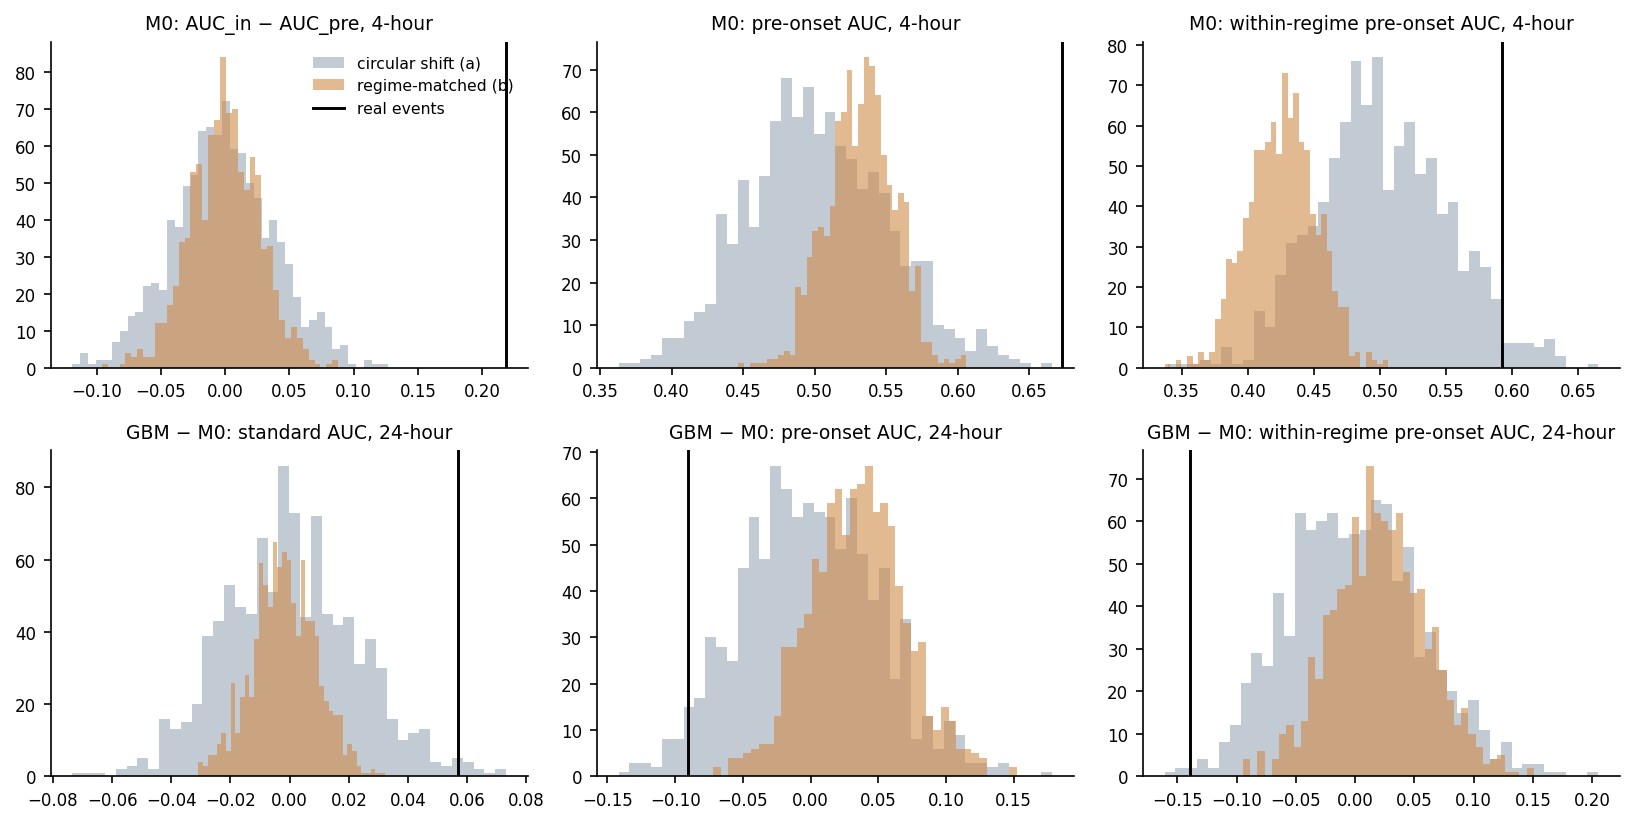

In [6]:
PANELS = [(H_REF, 'm0_in_minus_pre', 'M0: AUC_in − AUC_pre, 4-hour'), (H_REF, 'm0_auc_pre', 'M0: pre-onset AUC, 4-hour'),
          (H_REF, 'm0_auc_pre_within_regime', 'M0: within-regime pre-onset AUC, 4-hour'),
          (H_24, 'd_auc_standard', 'GBM − M0: standard AUC, 24-hour'), (H_24, 'd_auc_pre', 'GBM − M0: pre-onset AUC, 24-hour'),
          (H_24, 'd_auc_pre_within_regime', 'GBM − M0: within-regime pre-onset AUC, 24-hour')]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), dpi=150)
for ax, (H, col, title) in zip(axes.ravel(), PANELS):
    for fam, colr, lab in (('a', '#9aa7b8', 'circular shift (a)'), ('b', '#d08c4a', 'regime-matched (b)')):
        d = PD_[(PD_.family == fam) & (PD_.H == H)][col].to_numpy(float); d = d[np.isfinite(d)]
        ax.hist(d, bins=40, color=colr, alpha=0.6, label=lab)
    ax.axvline(real_value(H, col), color='black', lw=1.4, label='real events')
    ax.set_title(title, fontsize=9); ax.tick_params(labelsize=8); ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=7.5)
fig.tight_layout(); fig.savefig(OUT / 'fig_placebo.png'); fig.savefig(OUT / 'fig_placebo.pdf'); plt.show()

## 4. Summary

In [7]:
def _j(o):
    if isinstance(o, (np.floating, np.integer)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return str(o)


summary = dict(spec_sha256=SPEC_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'],
               mock_bypass_used=bool(any(g['bypassed_in_mock'] for g in GUARDS)), guards=GUARDS, common_minutes=int(MC.sum()),
               events_on_common_minutes={str(H): len(INFO[H][0]) for H in H_LIST},
               real={str(H): dict(m0={k: REAL[H][0][k] for k in KEYS}, gbm={k: REAL[H][1][k] for k in KEYS}) for H in H_LIST},
               readings=READ, reference=RF.to_dict('records'), placement=PL.to_dict('records'), outputs=sorted(p.name for p in OUT.iterdir() if p.is_file()))
(OUT / '42_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=_j))
print(f'guards: {sum(g["passed"] for g in GUARDS)} passed, {sum(not g["passed"] for g in GUARDS)} failed'
      + (f' (bypassed in the mock: {sorted({g["guard"] for g in GUARDS if g["bypassed_in_mock"]})})' if summary['mock_bypass_used'] else ''))
print('Done. Outputs in', OUT)

guards: 14 passed, 0 failed
Done. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/placebo_reference_v1


## Interpretation
- Placebo AUCs need not be 0.5. Family (b) places windows in the same volatility regime as the real events, so scores that move with volatility also score above 0.5 in placebo windows. That level is the regime-matched placebo reference, and I describe a real value beyond its range only as "beyond the placebo reference". Family (a) is a reference that does not match the regime but keeps label structure, event spacing and clustering.
- Family (b) matches the decile of the first window minute. For events whose onset precedes the window (slow declines), that minute already lies in the decline, so its decile carries the decline's own volatility and the placebo window lands in a more volatile period. In-progress minutes come mainly from such events, so AUC_in − AUC_pre can exceed 0 under (b) as well; this is the reference for an in-progress advantage produced by regime composition alone, and a conservative one for R1.
- `2_placebo_reference.csv` lists, for every statistic, the real value, the placebo median, the 2.5th and 97.5th percentiles and the empirical p; R1–R3 appear in the cell output and in `readings` of `42_SUMMARY.json`. `4_reversal_frequency.csv` gives the share of placebo draws with the real ordering (standard difference > 0, pre-onset difference < 0) and the share with both differences as extreme as the real ones; both are descriptive, not tests. When `placement_caution` in `3_placement_check.csv` is true, I append "(placement caution)" to that definition's readings.